## Ćwiczenie 6: Zadanie samodzielne – od detekcji krawędzi do wstępnej segmentacji - ROZWIĄZANIE

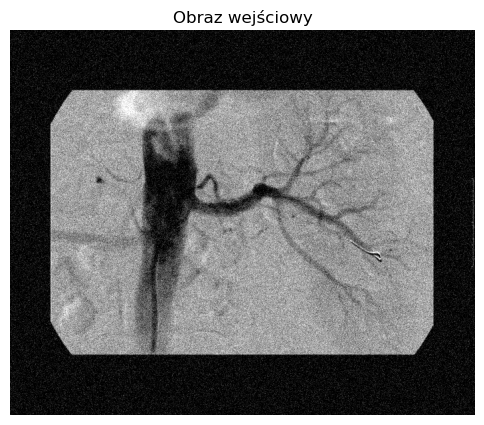

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, util, io

# 1. Wczytanie obrazu i dodanie szumu
image = data.camera() / 255.0

file_path = 'C:/Users/krzys/Digital Image Processing/sample photos/jpeg/stent.jpg'
image = io.imread(file_path, as_gray=True)
noisy_image = util.random_noise(image, mode='gaussian', var=0.01)

plt.figure(figsize=(6, 6))
plt.imshow(noisy_image, cmap='gray')
plt.title('Obraz wejściowy')
plt.axis('off')
plt.show()

### Krok 1: Wzmocnienie i Detekcja Krawędzi

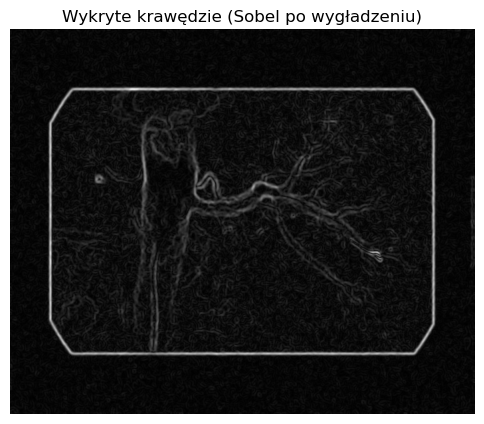

In [7]:
# Wygładzenie wstępne w celu redukcji szumu
smooth_img = filters.gaussian(noisy_image, sigma=1.5)

# Wyznaczenie modułu gradientu filtrem Sobela
edges = filters.sobel(smooth_img)

plt.figure(figsize=(6, 6))
plt.imshow(edges, cmap='gray')
plt.title('Wykryte krawędzie (Sobel po wygładzeniu)')
plt.axis('off')
plt.show()

### Krok 2: Progowanie (Binaryzacja krawędzi)

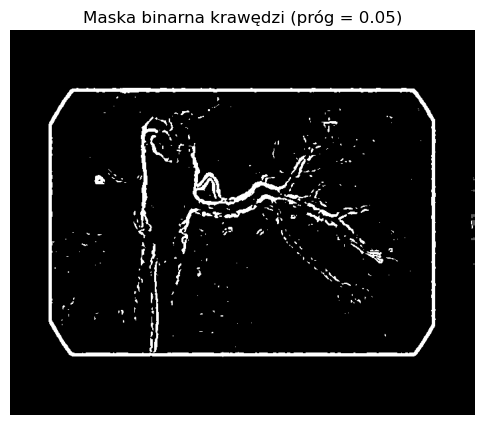

In [10]:
# Dobór progu do odrzucenia szumu tła i pozostawienia istotnych konturów
threshold = 0.05
binary_mask = edges > threshold

plt.figure(figsize=(6, 6))
plt.imshow(binary_mask, cmap='gray')
plt.title(f'Maska binarna krawędzi (próg = {threshold})')
plt.axis('off')
plt.show()

### Krok 3: Wnioski i Refleksja Kliniczna
Uzyskana maska krawędziowa rzadko bywa idealnie zamknięta. Lokalne spadki gradientu spowodowane niskim kontrastem tkanek prowadzą do przerw w ciągłości konturu. Przerwy te uniemożliwiają bezpośrednie zastosowanie algorytmów wypełniania obszarów (np. flood-fill) do automatycznego wyznaczenia objętości narządu, co wymusza stosowanie późniejszych operacji morfologicznych (dylatacja, domknięcie) lub zaawansowanych modeli aktywnych konturów.